<a href="https://colab.research.google.com/github/aulky/time-series-data-visualization/blob/main/notebooks/metro_interstate_traffic_submission_colab.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Time Series Analysis and Visualization of Metro Interstate Traffic Volume (2012–2018)

---
### Identitas Kelompok
- **Nama Anggota / NIM**:
  1. [Nama Lengkap] / [NIM]
  2. [Nama Lengkap] / [NIM]
  3. [Nama Lengkap] / [NIM]
  4. [Nama Lengkap] / [NIM]
- **Kelas**: [Kelas]
- **Dataset**: Metro Interstate Traffic Volume (UCI Machine Learning Repository ID: 492)

# 1. Project Overview

## 2. Dataset Description & Source

- **Sumber**: UCI Machine Learning Repository (ID: 492)
- **URL**: https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume
- **Variabel Utama**: `date_time`, `traffic_volume`

In [1]:
# 3. Setup & Library Imports (Kompatibel Google Colab & Lokal)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    print("[Colab] Menginstal dependensi...")
    !pip install -q ucimlrepo

    raw_dest = Path("data/raw/metro_interstate_traffic_volume.csv")
    if not raw_dest.exists():
        raw_dest.parent.mkdir(parents=True, exist_ok=True)
        import urllib.request
        url = "https://raw.githubusercontent.com/aulky/time-series-data-visualization/main/data/raw/metro_interstate_traffic_volume.csv"
        try:
            print("[Colab] Mengunduh raw dataset...")
            urllib.request.urlretrieve(url, raw_dest)
            print("[Colab] Dataset berhasil diunduh.")
        except Exception as e:
            print("[Colab] Fallback ke ucimlrepo...", e)
            from ucimlrepo import fetch_ucirepo
            import pandas as pd
            ds = fetch_ucirepo(id=492)
            pd.concat([ds.data.features, ds.data.targets], axis=1).to_csv(
                raw_dest, index=False, lineterminator="\n"
            )
    ROOT = Path.cwd()
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_PATH = ROOT / "data" / "raw" / "metro_interstate_traffic_volume.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "metro_interstate_traffic_model.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

# Konfigurasi path telah aktif pada sel setup

print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2


## 4. Data Loading

In [3]:
from hashlib import sha256

RAW_SHA256 = "312cb379ec73b71dc4d95c136e542c753690e943f43b49044d4ed80640fa2d76"
raw_bytes = RAW_PATH.read_bytes()
actual_sha = sha256(raw_bytes).hexdigest()

print("notebook root (relative to cwd):", ROOT.name, "| cwd:", Path.cwd().name)
print("raw file                 :", RAW_PATH.relative_to(ROOT))
print("sha256 actual            :", actual_sha)
print("sha256 expected          :", RAW_SHA256)
print("raw file unmodified      :", actual_sha == RAW_SHA256)
if actual_sha != RAW_SHA256:
    raise RuntimeError(
        "data/raw/metro_interstate_traffic_volume.csv does not match the expected UCI snapshot. "
        "Re-run `python scripts/download_data.py` before analysing."
    )

raw = pd.read_csv(RAW_PATH)
print("shape:", raw.shape)
raw.head()

notebook root (relative to cwd): time-series-data-visualization | cwd: notebooks
raw file                 : data\raw\metro_interstate_traffic_volume.csv
sha256 actual            : 312cb379ec73b71dc4d95c136e542c753690e943f43b49044d4ed80640fa2d76
sha256 expected          : 312cb379ec73b71dc4d95c136e542c753690e943f43b49044d4ed80640fa2d76
raw file unmodified      : True
shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
raw.tail(3)

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450
48203,NaN,282.12,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 23:00:00,954


## 5. Data Validation

### 5.1 Dimensi, tipe data, missing value

In [5]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_non_null": raw.notna().sum(),
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(3),
    "n_unique": raw.nunique(),
})

,dtype,n_non_null,n_missing,pct_missing,n_unique
holiday,str,61,48143,99.873,11
temp,float64,48204,0,0.000,5843
rain_1h,float64,48204,0,0.000,372
snow_1h,float64,48204,0,0.000,12
clouds_all,int64,48204,0,0.000,60
weather_main,str,48204,0,0.000,11
weather_description,str,48204,0,0.000,38
date_time,str,48204,0,0.000,40575
traffic_volume,int64,48204,0,0.000,6704


In [6]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
temp,48204.0,281.205870,13.338232,0.0,272.16,282.45,291.806,310.07
rain_1h,48204.0,0.334264,44.789133,0.0,0.00,0.00,0.000,9831.30
snow_1h,48204.0,0.000222,0.008168,0.0,0.00,0.00,0.000,0.51
clouds_all,48204.0,49.362231,39.015750,0.0,1.00,64.00,90.000,100.00
traffic_volume,48204.0,3259.818355,1986.860670,0.0,1193.00,3380.00,4933.000,7280.00


### 5.2 Konversi `date_time` dan urutan waktu

In [7]:
df = raw.copy()
df["date_time"] = pd.to_datetime(df["date_time"], format="%Y-%m-%d %H:%M:%S")
print("dtype:", df["date_time"].dtype)
print("monotonic increasing:", df["date_time"].is_monotonic_increasing)

dtype: datetime64[us]


monotonic increasing: True


### 5.3 Duplicate rows dan duplicate timestamps

In [8]:
print("fully duplicated rows (all 9 columns identical):", raw.duplicated().sum())
print("duplicated date_time values:", df["date_time"].duplicated().sum())
print("rows sharing a duplicated timestamp:", df["date_time"].duplicated(keep=False).sum())
print("holiday-labelled rows:", df["holiday"].notna().sum(),
      "| distinct dates:", df.loc[df["holiday"].notna(), "date_time"].dt.date.nunique())
print("hour-of-day of holiday-labelled rows:", df.loc[df["holiday"].notna(), "date_time"].dt.hour.unique())

fully duplicated rows (all 9 columns identical): 17


duplicated date_time values: 7629
rows sharing a duplicated timestamp: 13074
holiday-labelled rows: 61 | distinct dates: 53
hour-of-day of holiday-labelled rows: [0]


### 5.4 Timestamp ganda — periksa `traffic_volume` sebelum memutuskan

In [9]:
dup = df[df["date_time"].duplicated(keep=False)].sort_values(["date_time", "traffic_volume"])
groups = dup.groupby("date_time")["traffic_volume"].agg(n="size", vmin="min", vmax="max")
groups["spread"] = groups["vmax"] - groups["vmin"]

print("rows involved           :", len(dup))
print("duplicated timestamps   :", len(groups))
print("groups of size >2       :", int((groups["n"] > 2).sum()))
print("groups with spread == 0 :", int((groups["spread"] == 0).sum()))
print("groups with CONFLICTING traffic_volume:", int((groups["spread"] > 0).sum()))
print("date range:", dup["date_time"].min(), "->", dup["date_time"].max())

support = ["holiday", "temp", "rain_1h", "snow_1h", "clouds_all", "weather_main", "weather_description"]
diff = dup.groupby("date_time")[support].nunique(dropna=False)
print("\ngroups where every support column is identical:", int((diff.max(axis=1) == 1).sum()))
for col in ["temp", "rain_1h", "clouds_all", "weather_main", "weather_description", "holiday"]:
    print(f"  groups where {col:<20} differs:", int((diff[col] > 1).sum()))
num = dup.groupby("date_time")[["temp", "rain_1h", "snow_1h", "clouds_all"]]
print("max numeric spread inside a group:", (num.max() - num.min()).max().round(2).to_dict())
print("\nhour-of-day distribution of duplicated timestamps:")
print(groups.index.hour.value_counts().sort_index().to_string())

rows involved           : 13074
duplicated timestamps   : 5445
groups of size >2       : 1828
groups with spread == 0 : 5445
groups with CONFLICTING traffic_volume: 0
date range: 2012-10-10 07:00:00 -> 2018-09-30 15:00:00

groups where every support column is identical: 15
  groups where temp                 differs: 78
  groups where rain_1h              differs: 9
  groups where clouds_all           differs: 32
  groups where weather_main         differs: 5349
  groups where weather_description  differs: 5386
  groups where holiday              differs: 0
max numeric spread inside a group: {'temp': 20.43, 'rain_1h': 0.76, 'snow_1h': 0.0, 'clouds_all': 75.0}

hour-of-day distribution of duplicated timestamps:
date_time
0     232
1     246
2     242
3     267
4     283
5     276
6     287
7     300
8     281
9     259
10    255
11    205
12    192
13    166
14    190
15    181
16    201
17    194
18    204
19    195
20    188
21    192
22    194
23    215


In [10]:
dup.drop_duplicates().to_csv(ROOT / "reports" / "duplicate_timestamp_review.csv", index=False)
print("total residual duplicate rows after keep-first:", int(groups["n"].sub(1).sum()))

total residual duplicate rows after keep-first: 7629


### 5.8 Rentang tanggal, celah waktu, dan kelengkapan harian

#### Rentang tanggal

In [11]:
print("min:", df["date_time"].min())
print("max:", df["date_time"].max())
print("span:", df["date_time"].max() - df["date_time"].min())
df.groupby(df["date_time"].dt.year).size().rename("rows").to_frame().assign(
    distinct_timestamps=df.drop_duplicates("date_time").groupby(
        df.drop_duplicates("date_time")["date_time"].dt.year).size())

min: 2012-10-02 09:00:00
max: 2018-09-30 23:00:00
span: 2189 days 14:00:00


,rows,distinct_timestamps
date_time,,
2012,2559,2103
2013,8573,7294
2014,4839,4501
2015,4373,3593
2016,9306,7838
2017,10605,8713
2018,7949,6533


### 5.5 Timestamp gaps

In [12]:
full_index = pd.date_range("2012-10-02 09:00", "2018-09-30 23:00", freq="h")
observed = pd.DatetimeIndex(df["date_time"].drop_duplicates().sort_values())
missing = full_index.difference(observed)

print(f"expected hours : {len(full_index):,}")
print(f"observed hours : {len(observed):,}")
print(f"missing hours  : {len(missing):,} ({len(missing)/len(full_index)*100:.2f}%)")

steps = pd.Series(observed).diff().dropna().dt.total_seconds() / 3600
print("\nstep sizes between consecutive observations (hours -> count):")
print(steps.value_counts().sort_index().head(10))

expected hours : 52,551
observed hours : 40,575
missing hours  : 11,976 (22.79%)

step sizes between consecutive observations (hours -> count):
date_time
1.0     37986
2.0      2192
3.0       201
4.0        59
5.0        33
6.0        17
7.0        10
8.0        13
9.0        12
10.0       13
Name: count, dtype: int64


In [13]:
miss = pd.Series(1, index=missing)
blocks = (miss.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()
gaps = miss.groupby(blocks).agg(
    gap_start=lambda s: s.index[0],
    gap_end=lambda s: s.index[-1],
    n_missing_hours="size",
).sort_values("n_missing_hours", ascending=False)
gaps.to_csv(ROOT / "reports" / "timestamp_gaps.csv", index=False)

print("contiguous gaps:", len(gaps))
print("\ntop 10 gaps:")
display(gaps.head(10).reset_index(drop=True))
print("\ngap length distribution (hours -> #gaps):")
print(gaps["n_missing_hours"].value_counts().sort_index().to_string())
print("\nshare of all missing hours inside the single largest gap:",
      f"{gaps['n_missing_hours'].iloc[0] / gaps['n_missing_hours'].sum() * 100:.1f}%")

contiguous gaps: 2588

top 10 gaps:


,gap_start,gap_end,n_missing_hours
0,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
1,2013-10-27 02:00:00,2013-11-06 03:00:00,242
2,2015-06-14 21:00:00,2015-06-19 17:00:00,117
3,2014-04-29 09:00:00,2014-05-04 04:00:00,116
4,2015-10-23 12:00:00,2015-10-27 07:00:00,92
5,2014-07-27 17:00:00,2014-07-30 08:00:00,64
6,2013-08-31 01:00:00,2013-09-01 22:00:00,46
7,2015-06-22 19:00:00,2015-06-24 03:00:00,33
8,2014-08-02 03:00:00,2014-08-03 10:00:00,32
9,2013-09-03 03:00:00,2013-09-04 07:00:00,29



gap length distribution (hours -> #gaps):
n_missing_hours
1       2192
2        201
3         59
4         33
5         17
6         10
7         13
8         12
9         13
10         4
11         2
12         3
13         3
14         2
16         1
17         1
20         2
21         4
23         4
24         1
29         2
32         1
33         1
46         1
64         1
92         1
116        1
117        1
242        1
7386       1

share of all missing hours inside the single largest gap: 61.7%


In [14]:
dedup = df.drop_duplicates(subset="date_time", keep="first").copy()
daily = (dedup.assign(date=dedup["date_time"].dt.date)
              .groupby("date")
              .agg(n_obs=("date_time", "nunique"), mean_volume=("traffic_volume", "mean"))
              .reset_index())
daily["date"] = pd.to_datetime(daily["date"])
daily["is_boundary_day"] = daily["date"].isin(["2012-10-02", "2018-09-30"])
daily.to_csv(ROOT / "reports" / "daily_completeness.csv", index=False)

inner = daily.loc[~daily["is_boundary_day"]]
print("calendar days covered        :", len(daily))
print("complete 24h days            :", int((inner["n_obs"] == 24).sum()))
print("incomplete inner days        :", int((inner["n_obs"] < 24).sum()))
span_days = (daily["date"].max() - daily["date"].min()).days + 1
print("calendar days in span:", span_days, "| days present in index:", len(daily),
      "| days with zero recorded hours:", span_days - len(daily))
display(daily.loc[daily["is_boundary_day"]])
print("\nobservation-count distribution:")
print(daily["n_obs"].value_counts().sort_index().to_string())

calendar days covered        : 1860
complete 24h days            : 1214
incomplete inner days        : 646
calendar days in span: 2190 | days present in index: 1860 | days with zero recorded hours: 330


,date,n_obs,mean_volume,is_boundary_day



observation-count distribution:
n_obs
1        9
2        7
3        7
4        5
5        2
6        8
7        1
8        6
9        7
10       5
11      11
12      26
13      52
14      37
15      30
16      27
17      31
18      25
19      25
20      31
21      62
22      70
23     162
24    1214


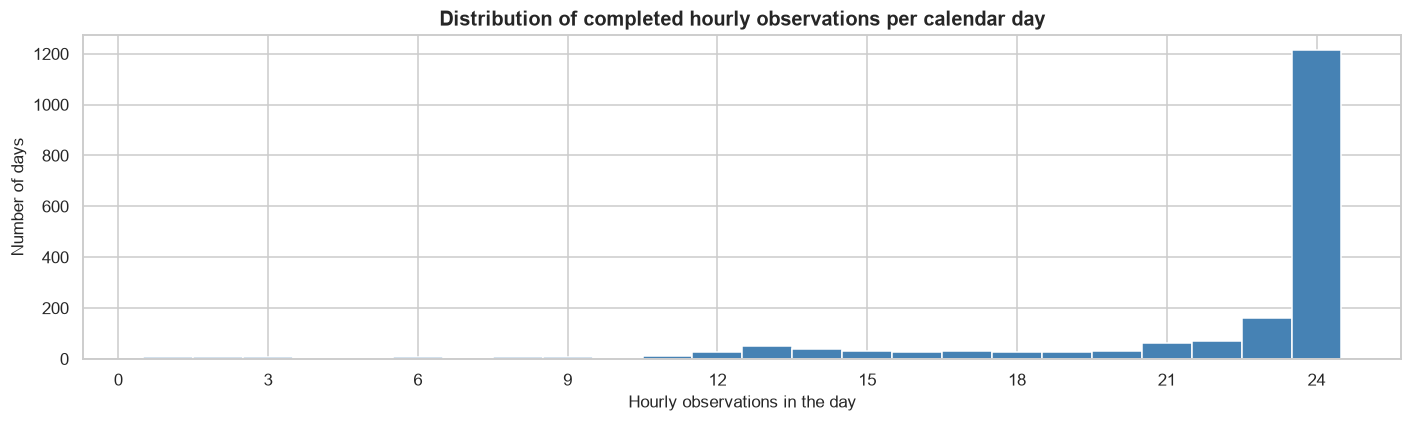

In [15]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.hist(daily["n_obs"], bins=np.arange(0.5, 25.5, 1), color="steelblue", edgecolor="white")
ax.set(title="Distribution of completed hourly observations per calendar day",
       xlabel="Hourly observations in the day", ylabel="Number of days")
ax.set_xticks(range(0, 25, 3))
plt.tight_layout()
plt.savefig(FIG_DIR / "10_validation_daily_completeness.png")
plt.show()

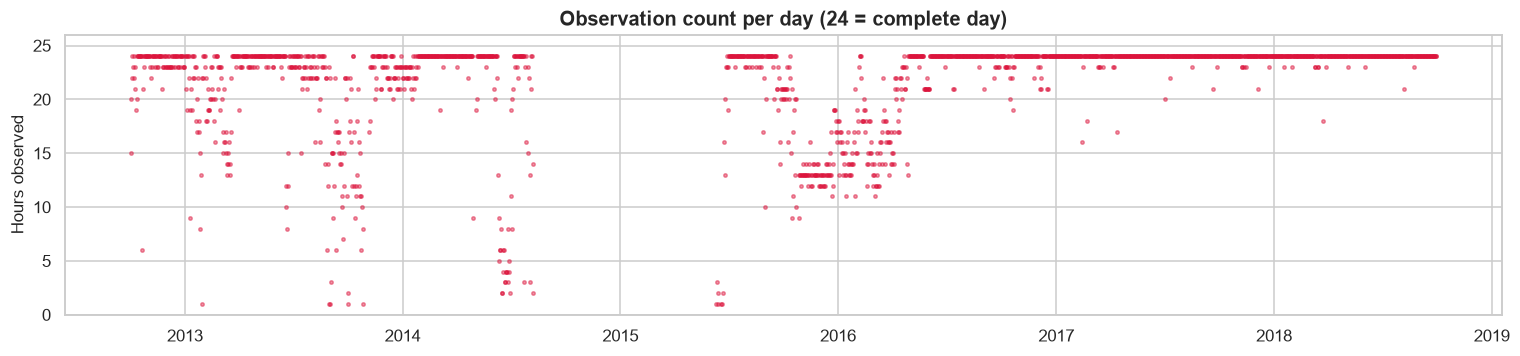

In [16]:
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.scatter(daily["date"], daily["n_obs"], s=5, alpha=0.45, color="crimson")
ax.set(title="Observation count per day (24 = complete day)", ylabel="Hours observed", ylim=(0, 26))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 5.9 Outlier `traffic_volume` dan nilai sentinel

#### Outlier `traffic_volume`

In [17]:
q1, q3 = dedup["traffic_volume"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flag = dedup["traffic_volume"].lt(low) | dedup["traffic_volume"].gt(high)
print(f"Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}  fences=({low:.0f}, {high:.0f})")
print(f"IQR outliers: {flag.sum()} rows ({flag.mean()*100:.2f}%)")
print("observed max:", dedup["traffic_volume"].max())
dedup.nlargest(5, "traffic_volume")[["date_time", "traffic_volume", "weather_main"]]

Q1=1248  Q3=4952  IQR=3704  fences=(-4307, 10507)
IQR outliers: 0 rows (0.00%)
observed max: 7280


,date_time,traffic_volume,weather_main
31615,2017-03-09 16:00:00,7280,Clouds
22640,2016-04-21 07:00:00,7260,Mist
22671,2016-04-22 07:00:00,7241,Clear
5619,2013-04-30 07:00:00,7217,Clear
43158,2018-04-12 16:00:00,7213,Clouds


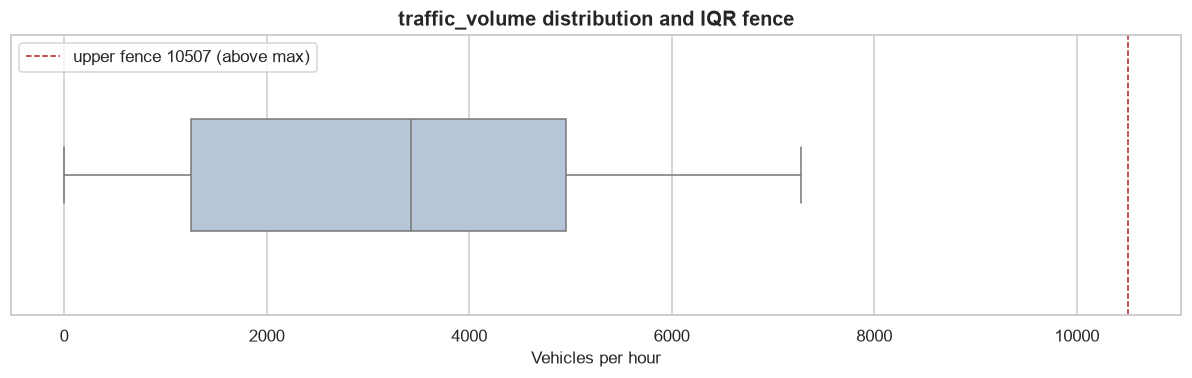

In [18]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.boxplot(x=dedup["traffic_volume"], ax=ax, color="lightsteelblue", width=0.4)
ax.axvline(high, color="firebrick", ls="--", lw=1, label=f"upper fence {high:.0f} (above max)")
ax.set(title="traffic_volume distribution and IQR fence", xlabel="Vehicles per hour")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "09_validation_volume_boxplot.png")
plt.show()

### 5.6 Volume nol

In [19]:
zeros = dedup[dedup["traffic_volume"] == 0]
print(f"zero-volume rows: {len(zeros)}")
print(zeros[["date_time", "traffic_volume", "temp", "clouds_all", "weather_main"]].to_string(index=False))

zero-volume rows: 2
          date_time  traffic_volume   temp  clouds_all weather_main
2016-07-23 18:00:00               0 296.68          40         Rain
2016-07-23 23:00:00               0 295.90          90         Haze


### 5.7 Nilai fisik mustahil dan label tidak konsisten

In [20]:
zero_k = dedup[dedup["temp"] <= 0]
rain_sentinel = dedup[dedup["rain_1h"] > 200]
case_variants = dedup.loc[dedup["weather_description"].ne(dedup["weather_description"].str.lower()),
                          "weather_description"].unique()

print("temp <= 0 K rows:", len(zero_k), "| dates:", sorted(zero_k["date_time"].dt.date.unique()))
print("rain_1h > 200 mm/h rows:", len(rain_sentinel))
display(rain_sentinel[["date_time", "rain_1h", "weather_main"]])
print("weather_description labels differing only by capitalisation:", case_variants)

temp <= 0 K rows: 10 | dates: [datetime.date(2014, 1, 31), datetime.date(2014, 2, 2)]
rain_1h > 200 mm/h rows: 1


,date_time,rain_1h,weather_main
24872,2016-07-11 17:00:00,9831.3,Rain


weather_description labels differing only by capitalisation: <StringArray>
['SQUALLS', 'Sky is Clear']
Length: 2, dtype: str


## 6. Data Preprocessing

In [21]:
proc = dedup.copy()
proc = proc.drop_duplicates(subset="date_time", keep="first")

proc["temp_c"] = proc["temp"] - 273.15
proc = proc.rename(columns={"temp": "temp_k"})
proc["is_temp_error"] = proc["temp_k"].le(0)
proc["is_rain_error"] = proc["rain_1h"].gt(200)
proc["temp_c_clean"] = proc["temp_c"].where(~proc["is_temp_error"])
proc["weather_description"] = proc["weather_description"].str.lower()

proc = proc.sort_values("date_time").reset_index(drop=True)
proc["holiday"] = proc["holiday"].astype(object).where(proc["holiday"].notna(), "None")
proc["date"] = proc["date_time"].dt.date
proc["hour"] = proc["date_time"].dt.hour
proc["day_of_week"] = proc["date_time"].dt.day_name()
proc["day_of_week_num"] = proc["date_time"].dt.day_of_week
proc["is_weekend"] = proc["day_of_week_num"] >= 5
proc["month"] = proc["date_time"].dt.month
proc["year"] = proc["date_time"].dt.year
proc["is_holiday"] = proc["holiday"].ne("None")
holiday_dates = set(proc.loc[proc["is_holiday"], "date"])
proc["holiday_date"] = proc["date"].where(proc["date"].isin(holiday_dates))
proc["is_sensor_zero"] = proc["traffic_volume"].eq(0)
proc["gap_hours"] = proc["date_time"].diff().dt.total_seconds().div(3600).fillna(0).astype(int)

print("shape:", proc.shape)
print("distribution of gap_hours >= 2 (hours missing before the row):")
print(proc.loc[proc["gap_hours"] >= 2, "gap_hours"].describe().round(2))
proc.head()

shape: (40575, 24)
distribution of gap_hours >= 2 (hours missing before the row):
count    2588.00
mean        5.63
std       145.30
min         2.00
25%         2.00
50%         2.00
75%         2.00
max      7387.00
Name: gap_hours, dtype: float64


,holiday,temp_k,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_c,...,hour,day_of_week,day_of_week_num,is_weekend,month,year,is_holiday,holiday_date,is_sensor_zero,gap_hours
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,...,9,Tuesday,1,False,10,2012,False,NaN,False,0
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,...,10,Tuesday,1,False,10,2012,False,NaN,False,1
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,...,11,Tuesday,1,False,10,2012,False,NaN,False,1
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,...,12,Tuesday,1,False,10,2012,False,NaN,False,1
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,...,13,Tuesday,1,False,10,2012,False,NaN,False,1


### 6.1 Simpan / verifikasi dataset processed

In [22]:
if PROCESSED_PATH.exists():
    existing = pd.read_csv(PROCESSED_PATH, parse_dates=["date_time"])
    assert list(existing.columns) == list(proc.columns), "column set differs from preprocessing script"
    same = True
    def as_text(s):
        # pandas' nullable "str" dtype reports NaN as the literal string "None"; treat both as <NA>
        return s.astype(object).map(lambda v: None if pd.isna(v) or v == "None" else str(v))

    for col in proc.columns:
        left = proc[col].reset_index(drop=True)
        right = existing[col]
        if pd.api.types.is_numeric_dtype(left) and pd.api.types.is_numeric_dtype(right):
            same &= bool(np.allclose(left, right, equal_nan=True))
        else:
            same &= as_text(left).equals(as_text(right))
    print("rows x cols:", proc.shape, "| processed file identical to notebook pipeline:", same)
else:
    PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)   # works on a clean checkout
    proc.to_csv(PROCESSED_PATH, index=False)
    print("wrote", PROCESSED_PATH.relative_to(ROOT), proc.shape)

rows x cols: (40575, 24) | processed file identical to notebook pipeline: True


## 7. Exploratory Data Analysis

### 7.1 Statistik deskriptif `traffic_volume`

In [23]:
tv = proc["traffic_volume"]
desc = tv.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1)
desc["skewness"] = round(tv.skew(), 2)
desc["kurtosis"] = round(tv.kurt(), 2)
desc["n_zero_hours"] = int(tv.eq(0).sum())
desc.to_frame("traffic_volume (vehicles/hour)")

,traffic_volume (vehicles/hour)
count,40575.00
mean,3290.70
std,1984.80
min,0.00
5%,341.00
25%,1248.50
50%,3427.00
75%,4952.00
95%,6217.00
max,7280.00


### 7.2 Distribusi volume kendaraan

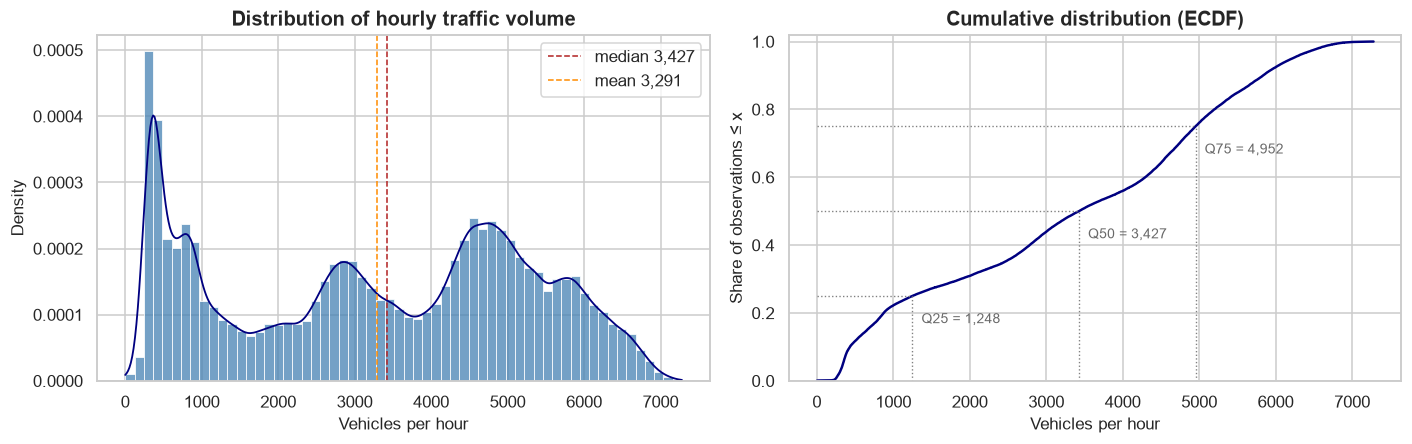

share of hours below 1,000 vehicles/h : 22.2%
share of hours above 5,000 vehicles/h : 23.9%


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(tv, bins=60, stat="density", color="steelblue", ax=axes[0])
kde_x = np.linspace(tv.min(), tv.max(), 400)
kde = gaussian_kde(tv, bw_method=0.05)
axes[0].plot(kde_x, kde(kde_x), color="navy", lw=1.2)
axes[0].axvline(tv.median(), color="firebrick", ls="--", lw=1,
                label=f"median {tv.median():,.0f}")
axes[0].axvline(tv.mean(), color="darkorange", ls="--", lw=1,
                label=f"mean {tv.mean():,.0f}")
axes[0].set(title="Distribution of hourly traffic volume", xlabel="Vehicles per hour",
            ylabel="Density")
axes[0].legend()

sorted_tv = np.sort(tv.values)
ecdf = np.arange(1, len(sorted_tv) + 1) / len(sorted_tv)
axes[1].plot(sorted_tv, ecdf, color="navy", lw=1.6)
for q in (0.25, 0.5, 0.75):
    value = tv.quantile(q)
    axes[1].plot([value, value], [0, q], color="gray", ls=":", lw=0.9)
    axes[1].plot([0, value], [q, q], color="gray", ls=":", lw=0.9)
    axes[1].annotate(f"Q{int(q*100)} = {value:,.0f}", xy=(value, q), xytext=(value + 120, q - 0.08),
                     fontsize=9, color="dimgray")
axes[1].set(title="Cumulative distribution (ECDF)", xlabel="Vehicles per hour",
            ylabel="Share of observations ≤ x", ylim=(0, 1.02))

plt.tight_layout()
plt.savefig(FIG_DIR / "06_eda_distribution.png")   # save before show(), otherwise the canvas is already blank
plt.show()

print(f"share of hours below 1,000 vehicles/h : {tv.lt(1000).mean()*100:.1f}%")
print(f"share of hours above 5,000 vehicles/h : {tv.gt(5000).mean()*100:.1f}%")

### 7.3 Rata-rata volume berdasarkan jam

lowest hours : {3: 373.0, 2: 393.0, 1: 521.0}
highest hours: {16: 5709.0, 17: 5351.0, 15: 5272.0}
weekday peak hours: {16: 6241.0, 7: 6061.0, 17: 5823.0, 15: 5629.0}
weekend peak hours: {13: 4408.0, 12: 4403.0, 14: 4393.0, 16: 4375.0}


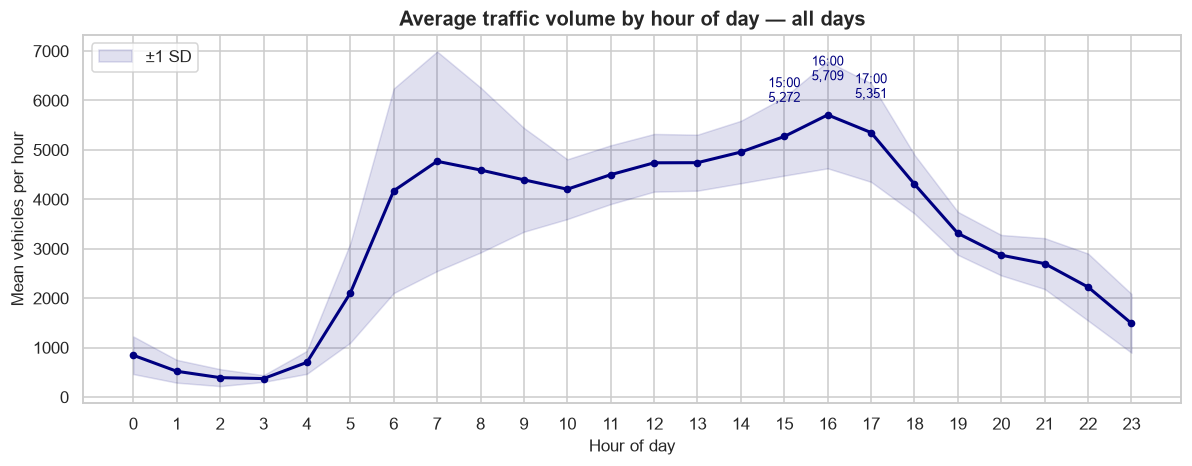

In [25]:
hourly_mean = proc.groupby("hour")["traffic_volume"].agg(mean="mean", sd="std", n="size")
print("lowest hours :", hourly_mean["mean"].nsmallest(3).round(0).to_dict())
print("highest hours:", hourly_mean["mean"].nlargest(3).round(0).to_dict())
for label, mask in [("weekday", ~proc["is_weekend"]), ("weekend", proc["is_weekend"])]:
    peaks = proc.loc[mask].groupby("hour")["traffic_volume"].mean().nlargest(4).round(0)
    print(f"{label} peak hours: {peaks.to_dict()}")

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(hourly_mean.index, hourly_mean["mean"], marker="o", ms=4, lw=2, color="navy")
ax.fill_between(hourly_mean.index, hourly_mean["mean"] - hourly_mean["sd"],
                hourly_mean["mean"] + hourly_mean["sd"], color="navy", alpha=0.12, label="±1 SD")
for h in hourly_mean["mean"].nlargest(3).index:
    ax.annotate(f"{h:02d}:00\n{hourly_mean['mean'][h]:,.0f}", xy=(h, hourly_mean["mean"][h]),
                xytext=(h, hourly_mean["mean"][h] + 700), ha="center", fontsize=8.5, color="navy")
ax.set(title="Average traffic volume by hour of day — all days",
       xlabel="Hour of day", ylabel="Mean vehicles per hour", xticks=range(24))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 7.4 Rata-rata volume berdasarkan hari

In [26]:
week_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_dim = (proc.groupby("day_of_week")["traffic_volume"]
             .agg(mean="mean", median="median", n="size").reindex(week_order))
daily_dim.round(0)

,mean,median,n
day_of_week,,,
Monday,3314.0,3615.0,5799
Tuesday,3535.0,4197.0,5703
Wednesday,3608.0,4362.0,5803
Thursday,3654.0,4350.0,5797
Friday,3675.0,4325.0,5877
Saturday,2823.0,3063.0,5784
Sunday,2426.0,2374.0,5812


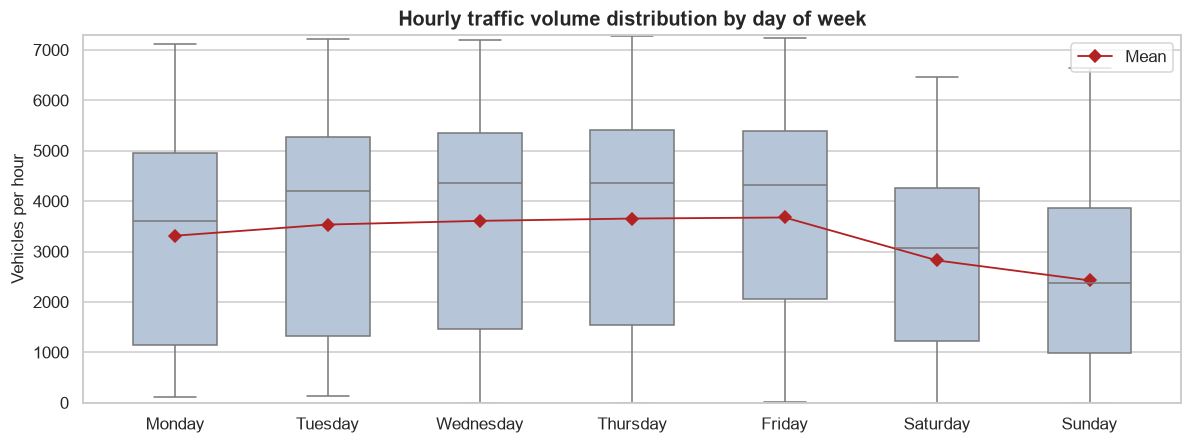

In [27]:
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=proc, x="day_of_week", y="traffic_volume", order=week_order,
            color="lightsteelblue", width=0.55, showfliers=False, ax=ax)
ax.plot(range(7), daily_dim["mean"], marker="D", ms=6, color="firebrick", lw=1.2, label="Mean")
ax.set(title="Hourly traffic volume distribution by day of week",
       xlabel="", ylabel="Vehicles per hour", ylim=(0, 7300))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 7.5 Weekday dibandingkan weekend

In [28]:
wd = proc.loc[~proc["is_weekend"], "traffic_volume"]
we = proc.loc[proc["is_weekend"], "traffic_volume"]
cmp_ = pd.DataFrame({
    "n_hours": [len(wd), len(we)],
    "mean": [wd.mean(), we.mean()],
    "median": [wd.median(), we.median()],
    "% hours < 1,000": [wd.lt(1000).mean() * 100, we.lt(1000).mean() * 100],
}, index=["Weekday (Mon–Fri)", "Weekend (Sat–Sun)"]).round(1)
print(f"mean difference: {wd.mean() - we.mean():,.0f} vehicles/h "
      f"({(wd.mean() / we.mean() - 1) * 100:.0f}% higher on weekdays)")
cmp_

mean difference: 934 vehicles/h (36% higher on weekdays)


,n_hours,mean,median,"% hours < 1,000"
Weekday (Mon–Fri),28979,3557.4,4159.0,21.7
Weekend (Sat–Sun),11596,2623.9,2770.5,23.7


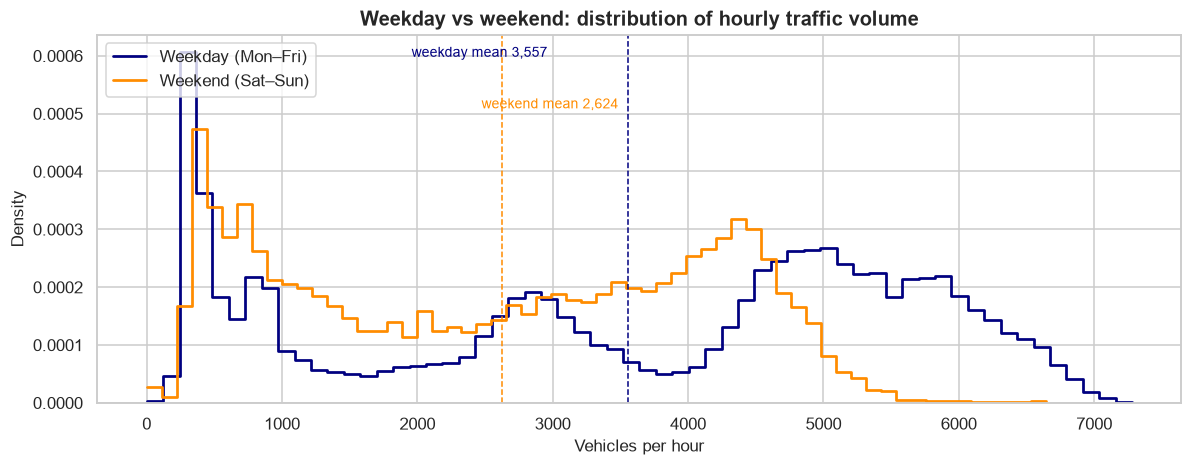

In [29]:
fig, ax = plt.subplots(figsize=(11, 4.4))
for label, series, color in [("Weekday (Mon–Fri)", wd, "navy"), ("Weekend (Sat–Sun)", we, "darkorange")]:
    sns.histplot(series, bins=60, stat="density", element="step", fill=False, lw=1.8,
                 color=color, label=label, ax=ax)
ax.axvline(wd.mean(), color="navy", ls="--", lw=1)
ax.axvline(we.mean(), color="darkorange", ls="--", lw=1)
ax.annotate(f"weekday mean {wd.mean():,.0f}", xy=(wd.mean(), ax.get_ylim()[1] * 0.99),
            xytext=(wd.mean() - 1600, ax.get_ylim()[1] * 0.94), fontsize=9, color="navy")
ax.annotate(f"weekend mean {we.mean():,.0f}", xy=(we.mean(), ax.get_ylim()[1] * 0.86),
            xytext=(we.mean() - 150, ax.get_ylim()[1] * 0.80), fontsize=9, color="darkorange")
ax.set(title="Weekday vs weekend: distribution of hourly traffic volume",
       xlabel="Vehicles per hour", ylabel="Density")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_eda_weekday_vs_weekend.png")
plt.show()

### 7.6 Rata-rata volume berdasarkan bulan

{'Jan': 3060.0, 'Feb': 3231.0, 'Mar': 3382.0, 'Apr': 3374.0, 'May': 3378.0, 'Jun': 3422.0, 'Jul': 3238.0, 'Aug': 3430.0, 'Sep': 3319.0, 'Oct': 3388.0, 'Nov': 3216.0, 'Dec': 3040.0}


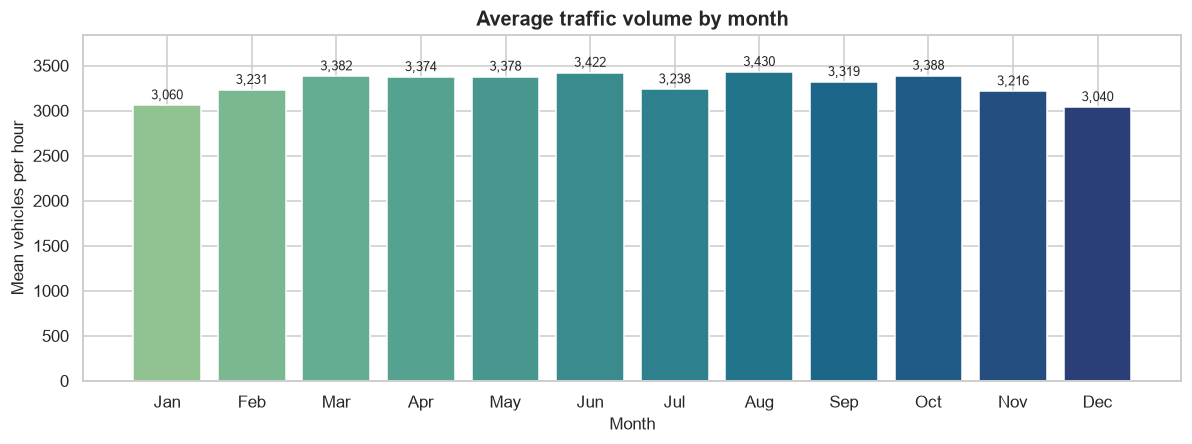

In [30]:
month_mean = proc.groupby("month")["traffic_volume"].agg(mean="mean", n="size")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_mean.index = month_names
print(month_mean["mean"].round(0).to_dict())

fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.bar(month_mean.index, month_mean["mean"], color=sns.color_palette("crest", 12))
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in month_mean["mean"]], fontsize=8.5, padding=2)
ax.set(title="Average traffic volume by month", xlabel="Month", ylabel="Mean vehicles per hour",
       ylim=(0, month_mean["mean"].max() * 1.12))
plt.tight_layout()
plt.show()

### 7.7 Pemeriksaan kelengkapan data temporal

In [31]:
gap = gaps.iloc[0]
print("largest gap:", gap["gap_start"], "->", gap["gap_end"], f"({gap['n_missing_hours']:,} hours)")

largest gap: 2014-08-08 02:00:00 -> 2015-06-11 19:00:00 (7,386 hours)


In [32]:
completeness = pd.DataFrame({
    "calendar days in span": [ (full_index[-1].normalize() - full_index[0].normalize()).days + 1 ],
    "days with any record": [proc["date"].nunique()],
    "days with 0 records": [int(((full_index[-1].normalize() - full_index[0].normalize()).days + 1)
                               - proc["date"].nunique())],
    "days with 24 records": [int((daily["n_obs"] == 24).sum())],
    "days with 1–23 records": [int(((daily["n_obs"] >= 1) & (daily["n_obs"] < 24)).sum())],
    "expected hours": [len(full_index)],
    "observed hours": [len(proc)],
    "missing hours": [len(missing)],
}, index=["value"]).T
completeness["share_of_expected"] = (completeness["value"] / len(full_index)).round(3)
completeness

,value,share_of_expected
calendar days in span,2190,0.042
days with any record,1860,0.035
days with 0 records,330,0.006
days with 24 records,1214,0.023
days with 1–23 records,646,0.012
expected hours,52551,1.000
observed hours,40575,0.772
missing hours,11976,0.228


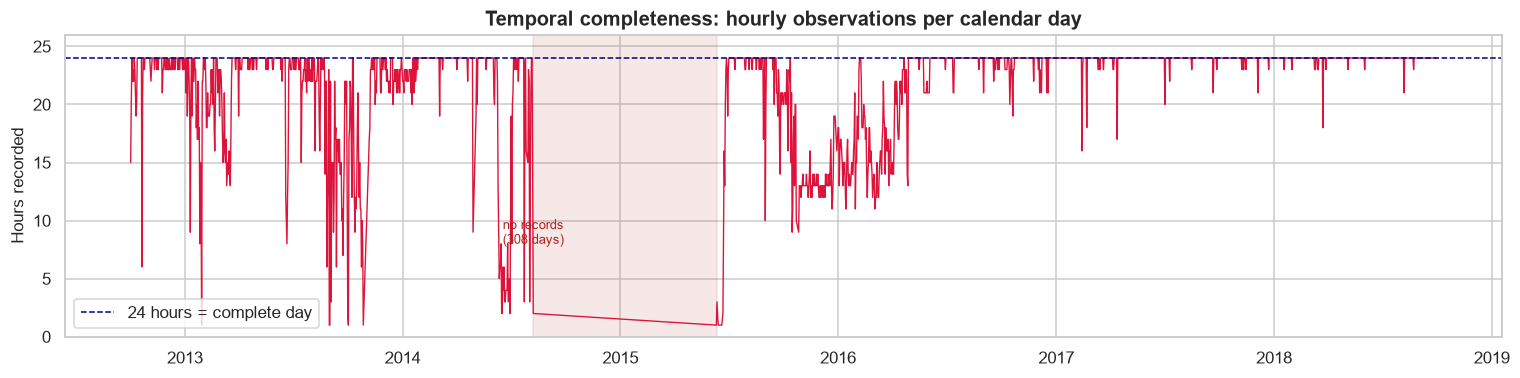

In [33]:
fig, ax = plt.subplots(figsize=(14, 3.6))
daily_plot = daily.copy()
daily_plot.loc[daily_plot["is_boundary_day"], "n_obs"] = daily_plot.loc[daily_plot["is_boundary_day"], "n_obs"]
ax.plot(daily_plot["date"], daily_plot["n_obs"], color="crimson", lw=0.9)
ax.axhline(24, color="navy", ls="--", lw=1, label="24 hours = complete day")
ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)
ax.annotate("no records\n(308 days)", xy=(pd.Timestamp(gap["gap_start"].normalize()), 5),
            xytext=(pd.Timestamp(gap["gap_start"].normalize()), 8), ha="center", fontsize=8.5,
            color="firebrick")
ax.set(title="Temporal completeness: hourly observations per calendar day",
       xlabel="", ylabel="Hours recorded", ylim=(0, 26))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_eda_temporal_completeness.png")
plt.show()

## 8. Line Plot — Daily Average Traffic Volume 2012–2018

line window: 2013-01-01 .. 2018-09-30 | 1769 days with data / 2099 days
daily average: min 277, median 3,483, max 5,263


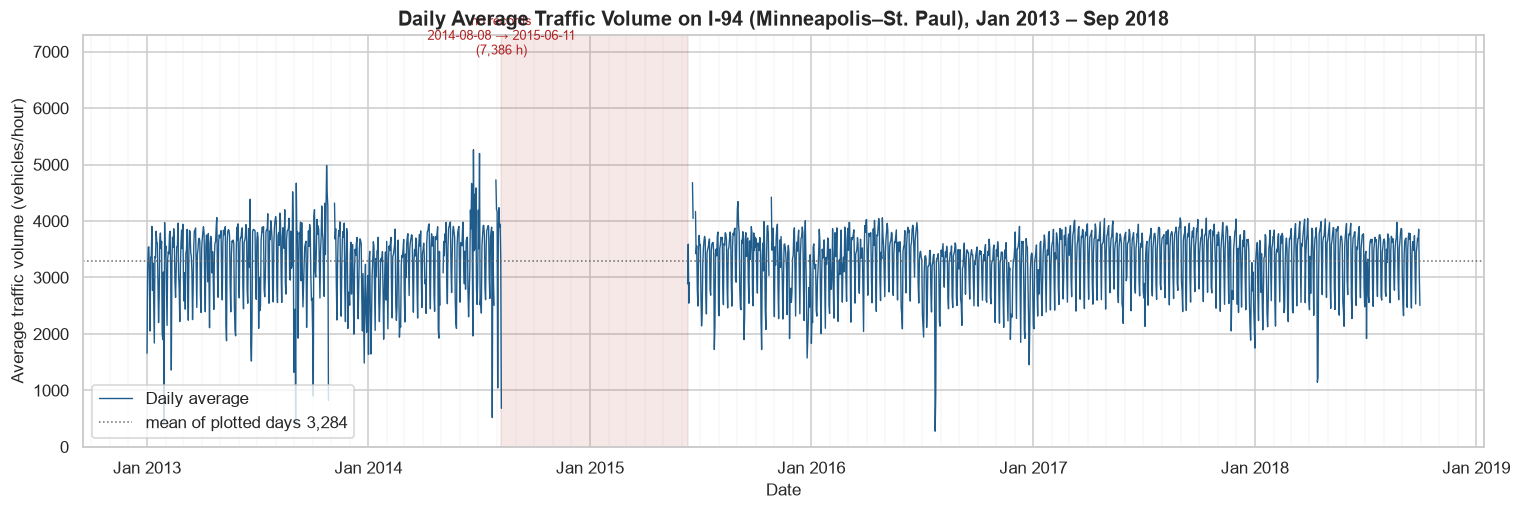

In [34]:
daily_avg = (proc.set_index("date_time")["traffic_volume"]
             .resample("D").mean())            # missing days -> NaN (no interpolation, no fillna)
plot_start, plot_end = pd.Timestamp("2013-01-01"), pd.Timestamp("2018-09-30")
line_data = daily_avg.loc[plot_start:plot_end]
print(f"line window: {plot_start.date()} .. {plot_end.date()} | "
      f"{line_data.notna().sum()} days with data / {len(line_data)} days")
print(f"daily average: min {line_data.min():,.0f}, median {line_data.median():,.0f}, "
      f"max {line_data.max():,.0f}")

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(line_data.index, line_data.values, color="#1f5c8b", lw=0.9, label="Daily average")
ax.axhline(line_data.mean(), color="dimgray", ls=":", lw=1,
           label=f"mean of plotted days {line_data.mean():,.0f}")
ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)
ax.annotate("no records\n2014-08-08 → 2015-06-11\n(7,386 h)", xy=(pd.Timestamp(gap["gap_start"]), 6800),
            xytext=(pd.Timestamp(gap["gap_start"]), 6950), color="firebrick", fontsize=8.5, ha="center")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set(title="Daily Average Traffic Volume on I-94 (Minneapolis–St. Paul), Jan 2013 – Sep 2018",
       xlabel="Date", ylabel="Average traffic volume (vehicles/hour)", ylim=(0, 7300))
ax.grid(axis="x", which="minor", alpha=0.15)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_line_plot.png")
plt.show()

## 9. Area Plot — Daily Traffic Volume (total per tanggal)

In [35]:
daily_total = (proc.groupby("date")["traffic_volume"]
               .agg(["sum", "size"]).rename(columns={"sum": "total", "size": "n_obs"}).reset_index())
daily_total["date"] = pd.to_datetime(daily_total["date"])
daily_total["complete"] = daily_total["n_obs"].eq(24)
full_days_total = daily_total.loc[daily_total["complete"]]
partial_days_total = daily_total.loc[~daily_total["complete"]]

print(f"complete days (24 h)          : {len(full_days_total)}")
print(f"partial days (<24 h)          : {len(partial_days_total)}")
print(f"total on complete days        : min {full_days_total['total'].min():,}, "
      f"median {full_days_total['total'].median():,.0f}, max {full_days_total['total'].max():,} "
      f"({full_days_total.loc[full_days_total['total'].idxmax(), 'date'].date()})")
print(f"median total, partial days    : {partial_days_total['total'].median():,.0f} "
      f"({partial_days_total['total'].median() / full_days_total['total'].median() * 100:.0f}% of a complete day)")

complete days (24 h)          : 1214
partial days (<24 h)          : 646
total on complete days        : min 6,654, median 84,068, max 97,332 (2017-08-31)
median total, partial days    : 58,317 (69% of a complete day)


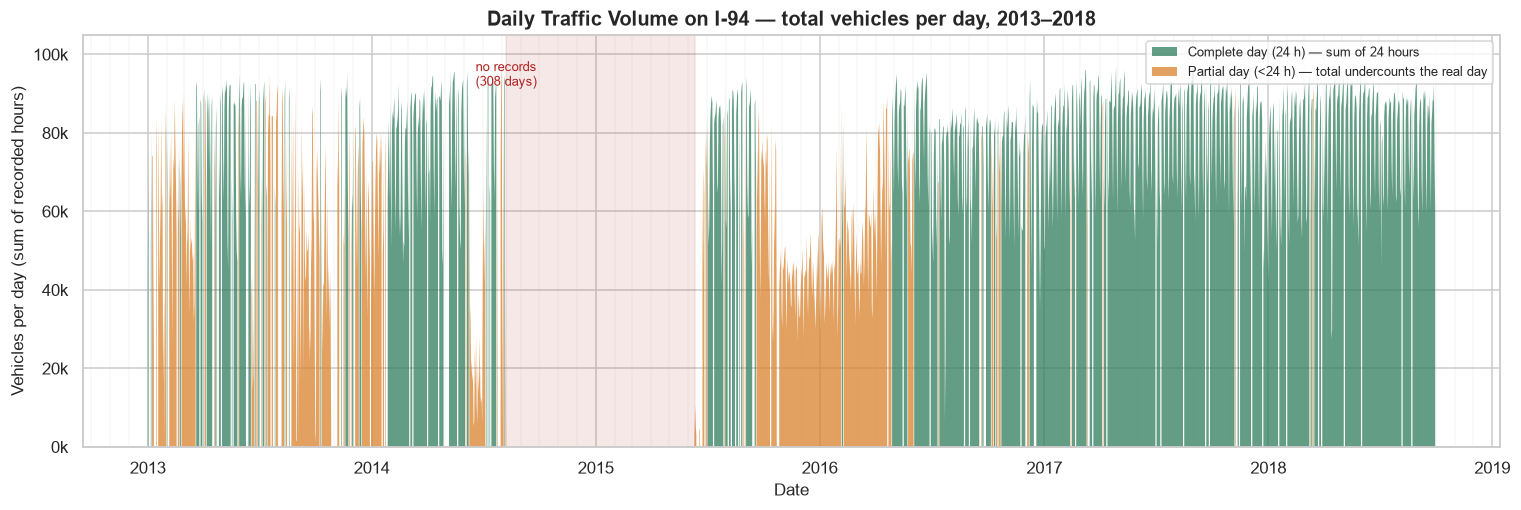

In [36]:
fig, ax = plt.subplots(figsize=(14, 4.8))

full_plot = full_days_total.set_index("date")["total"].reindex(
    pd.date_range(plot_start, plot_end, freq="D"))
partial_plot = partial_days_total.set_index("date")["total"].reindex(
    pd.date_range(plot_start, plot_end, freq="D"))

ax.fill_between(full_plot.index, full_plot.values, color="#2f7d5d", alpha=0.75,
                linewidth=0, label="Complete day (24 h) — sum of 24 hours")
ax.fill_between(partial_plot.index, partial_plot.values, color="#d9822b", alpha=0.75,
                linewidth=0, label="Partial day (<24 h) — total undercounts the real day")

ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)
ax.annotate("no records\n(308 days)", xy=(pd.Timestamp(gap["gap_start"].normalize()), 90000),
            xytext=(pd.Timestamp(gap["gap_start"].normalize()), 92000), color="firebrick", fontsize=8.5,
            ha="center")
ax.set(title="Daily Traffic Volume on I-94 — total vehicles per day, 2013–2018",
       xlabel="Date", ylabel="Vehicles per day (sum of recorded hours)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set_ylim(0, 105000)
ax.grid(axis="x", which="minor", alpha=0.15)
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_area_plot.png")
plt.show()

## 10. Multiple Time Series — Weekday vs Weekend (rata-rata per minggu pengamatan)

In [37]:
week = proc.assign(week=proc["date_time"].dt.to_period("W-SUN").dt.start_time)
weekly = (week.groupby(["week", "is_weekend"])["traffic_volume"]
          .agg(mean="mean", n_hours="size")
          .reset_index())
required = {False: 120, True: 48}
weekly["expected"] = weekly["is_weekend"].map(required)
weekly["complete"] = weekly["n_hours"].eq(weekly["expected"])
print(f"weeks total            : {weekly['week'].nunique()}")
print(f"weekday weeks complete : {weekly.loc[~weekly['is_weekend'], 'complete'].sum():,} / "
      f"{(~weekly['is_weekend']).sum():,}")
print(f"weekend weeks complete : {weekly.loc[weekly['is_weekend'], 'complete'].sum():,} / "
      f"{weekly['is_weekend'].sum():,}")
print(f"complete weeks with BOTH groups complete: {weekly[weekly['complete']].groupby('week').size().eq(2).sum():,}")

weeks total            : 269
weekday weeks complete : 114 / 269
weekend weeks complete : 157 / 267
complete weeks with BOTH groups complete: 101


weekday weekly mean: 3,559 (min 2,749, max 3,904), 111 weeks
weekend weekly mean: 2,636 (min 603, max 3,221), 155 weeks
line segments — weekday: 10 | weekend: 10
vertical gap between labels: 1,518 vehicles/h


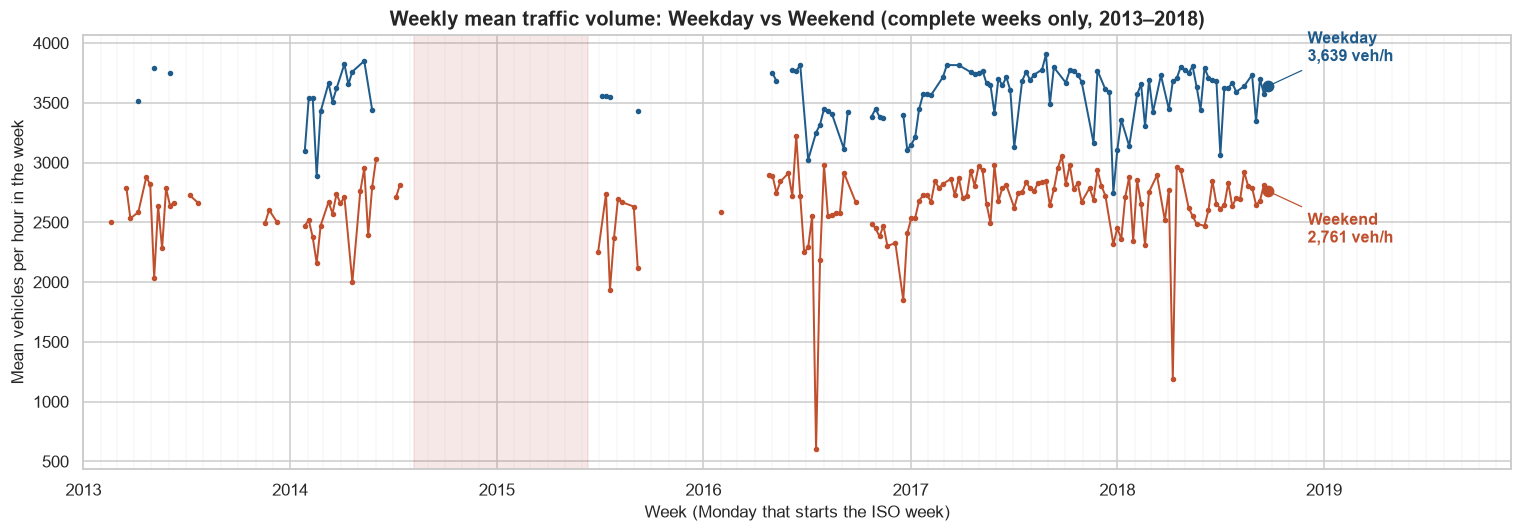

In [38]:
wd_week = (weekly.loc[(~weekly["is_weekend"]) & weekly["complete"]]
           .set_index("week")["mean"].sort_index())
we_week = (weekly.loc[(weekly["is_weekend"]) & weekly["complete"]]
           .set_index("week")["mean"].sort_index())
wd_week = wd_week.loc[wd_week.index >= plot_start]
we_week = we_week.loc[we_week.index >= plot_start]
MAX_WEEK_GAP = pd.Timedelta(weeks=3)   # a longer run of incomplete weeks is shown as a break, not a line

print(f"weekday weekly mean: {wd_week.mean():,.0f} (min {wd_week.min():,.0f}, max {wd_week.max():,.0f}), "
      f"{len(wd_week)} weeks")
print(f"weekend weekly mean: {we_week.mean():,.0f} (min {we_week.min():,.0f}, max {we_week.max():,.0f}), "
      f"{len(we_week)} weeks")

def segmented(series):
    # split where consecutive complete weeks are further apart than MAX_WEEK_GAP
    breaks = series.index.to_series().diff().gt(MAX_WEEK_GAP).cumsum()
    return [seg for _, seg in series.groupby(breaks.values)]

weekday_segments, weekend_segments = segmented(wd_week), segmented(we_week)
print("line segments — weekday:", len(weekday_segments), "| weekend:", len(weekend_segments))

fig, ax = plt.subplots(figsize=(14, 5.0))
for seg in weekday_segments:
    ax.plot(seg.index, seg.values, color="#1f5c8b", lw=1.3, marker="o", ms=2.6)
for seg in weekend_segments:
    ax.plot(seg.index, seg.values, color="#c0502d", lw=1.3, marker="o", ms=2.6)
ax.plot([], [], color="#1f5c8b", lw=1.3, marker="o", ms=2.6, label="Weekday")
ax.plot([], [], color="#c0502d", lw=1.3, marker="o", ms=2.6, label="Weekend")
ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)

# direct labels at the right end of each line, vertically separated
end_x = max(wd_week.index[-1], we_week.index[-1])
end_wd, end_we = wd_week.iloc[-1], we_week.iloc[-1]
ax.scatter([end_x], [end_wd], s=45, color="#1f5c8b", zorder=5, clip_on=False)
ax.scatter([end_x], [end_we], s=45, color="#c0502d", zorder=5, clip_on=False)
ax.annotate(f"Weekday\n{end_wd:,.0f} veh/h", xy=(end_x, end_wd),
            xytext=(end_x + pd.Timedelta(days=70), end_wd + 320), color="#1f5c8b",
            fontsize=10.5, fontweight="bold", ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color="#1f5c8b", lw=0.8))
ax.annotate(f"Weekend\n{end_we:,.0f} veh/h", xy=(end_x, end_we),
            xytext=(end_x + pd.Timedelta(days=70), end_we - 320), color="#c0502d",
            fontsize=10.5, fontweight="bold", ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color="#c0502d", lw=0.8))
print(f"vertical gap between labels: {abs((end_wd + 320) - (end_we - 320)):,.0f} vehicles/h")

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set_xlim(plot_start, end_x + pd.Timedelta(days=430))
ax.set(title="Weekly mean traffic volume: Weekday vs Weekend (complete weeks only, 2013–2018)",
       xlabel="Week (Monday that starts the ISO week)", ylabel="Mean vehicles per hour in the week")
ax.grid(axis="x", which="minor", alpha=0.15)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_multiple_time_series.png")
plt.show()

## 11. Seasonal Heatmap — hari × jam

In [39]:
heat = (proc.pivot_table(index="day_of_week", columns="hour", values="traffic_volume",
                       aggfunc="mean").reindex(week_order))
heat_n = (proc.pivot_table(index="day_of_week", columns="hour", values="traffic_volume",
                           aggfunc="size").reindex(week_order))
print(f"cells: {heat.size} | min observations per cell: {heat_n.min().min()} "
      f"(at {heat_n.stack().idxmin()}) | max: {heat_n.max().max()}")
print(f"value range: {heat.min().min():,.0f} .. {heat.max().max():,.0f}")
print("busiest cell :", f"{heat.stack().idxmax()[0]} {heat.stack().idxmax()[1]:02d}:00 -> "
      f"{heat.stack().max():,.0f}")
print("quietest cell:", f"{heat.stack().idxmin()[0]} {heat.stack().idxmin()[1]:02d}:00 -> "
      f"{heat.stack().min():,.0f}")

cells: 168 | min observations per cell: 227 (at ('Tuesday', np.int32(7))) | max: 256
value range: 277 .. 6,414
busiest cell : Wednesday 16:00 -> 6,414
quietest cell: Tuesday 02:00 -> 277


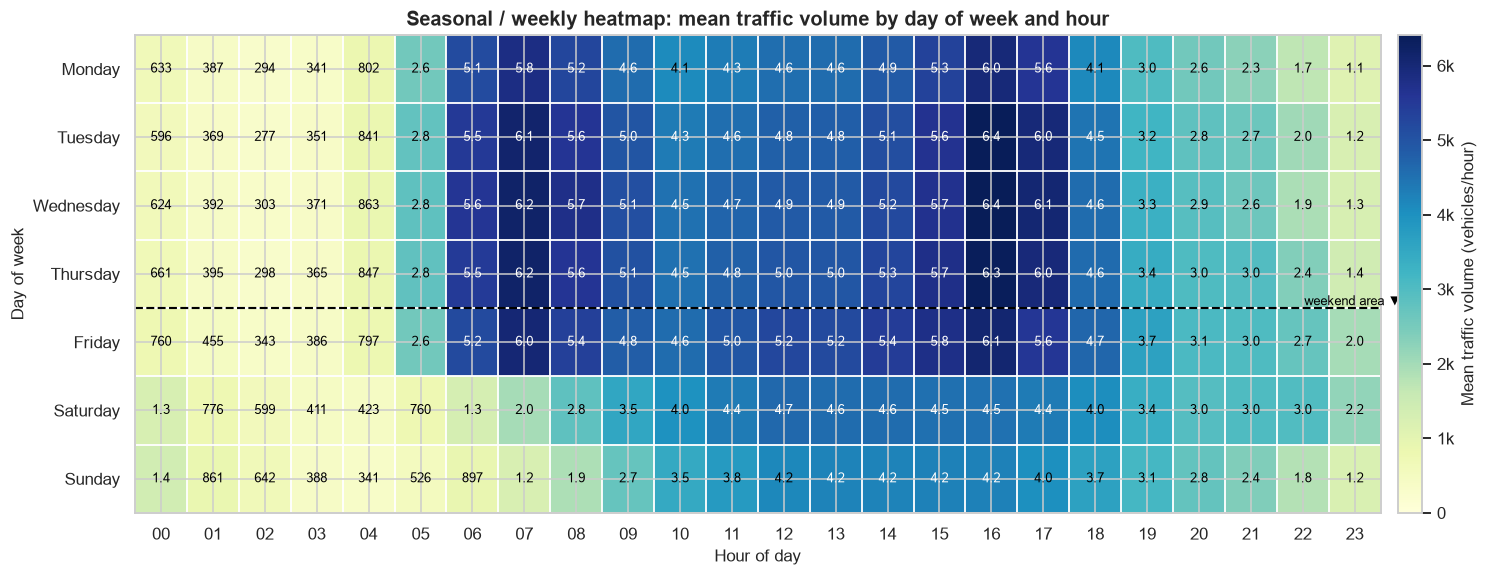

weekday mean by hour, peak: {16: 6239.0, 7: 6064.0, 17: 5826.0}
weekday mean by hour, trough: {2: 303.0, 3: 363.0}
12:00-15:00 mean — weekend 4,391 vs weekday 5,360 (-18.1%)
weekend maximum cell: Saturday 12:00 -> 4,651
weekend 06:00-09:00 vs weekday 06:00-09:00: 2383.0 vs 5250.0


In [40]:
fig, ax = plt.subplots(figsize=(15, 5.4))
im = ax.imshow(heat.values, aspect="auto", cmap="YlGnBu", vmin=0)
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7), week_order)
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 7, 1), minor=True)
ax.grid(which="minor", color="white", lw=1.2)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Day of week")
for (r, c), value in np.ndenumerate(heat.values):
    ax.text(c, r, f"{value/1000:.1f}" if value >= 1000 else f"{value:.0f}",
            ha="center", va="center", fontsize=8.5,
            color="white" if value > 4200 else "black")
ax.axhline(3.5, color="black", lw=1.4, ls="--")   # separates Fri (row 4) and Sat (row 5)
ax.text(23.9, 3.5, "weekend area ▼", ha="right", va="bottom", fontsize=8.5, color="black")
cbar = fig.colorbar(im, ax=ax, pad=0.012)
cbar.set_label("Mean traffic volume (vehicles/hour)")
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k" if v >= 1000 else f"{v:.0f}"))
ax.set_title("Seasonal / weekly heatmap: mean traffic volume by day of week and hour")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_seasonal_heatmap.png")
plt.show()

day_core = heat.loc[week_order[:5]].mean()
print("weekday mean by hour, peak:", day_core.nlargest(3).round(0).to_dict())
print("weekday mean by hour, trough:", day_core.nsmallest(2).round(0).to_dict())
weekend_midday = heat.loc[["Saturday", "Sunday"], 12:16].values.mean()
weekday_midday = heat.loc[week_order[:5], 12:16].values.mean()
print(f"12:00-15:00 mean — weekend {weekend_midday:,.0f} vs weekday {weekday_midday:,.0f} "
      f"({weekend_midday / weekday_midday - 1:+.1%})")
print("weekend maximum cell:", f"{heat.loc[['Saturday','Sunday']].stack().idxmax()[0]} "
      f"{heat.loc[['Saturday','Sunday']].stack().idxmax()[1]:02d}:00 -> "
      f"{heat.loc[['Saturday','Sunday']].stack().max():,.0f}")
print("weekend 06:00-09:00 vs weekday 06:00-09:00:",
      round(heat.loc[["Saturday", "Sunday"], 6:10].values.mean(), 0), "vs",
      round(heat.loc[week_order[:5], 6:10].values.mean(), 0))

## 12. Trend Analysis (Moving Average)

In [41]:
daily = daily_avg.loc[plot_start:plot_end]            # tanggal berurutan, satu baris per hari
ma7 = daily.rolling(window=7, min_periods=7).mean()   # SMA 7 hari (siklus mingguan)
ma30 = daily.rolling(window=30, min_periods=30).mean() # SMA 30 hari (siklus bulanan kasar)

print(f"indeks harian          : {daily.index[0].date()} ... {daily.index[-1].date()} "
      f"({len(daily):,} baris, monoton naik: {daily.index.is_monotonic_increasing})")
print(f"hari dengan data       : {daily.notna().sum():,} | hari tanpa data (NaN, tidak diisi): {daily.isna().sum():,}")
print(f"titik valid MA7        : {ma7.notna().sum():,} | MA30: {ma30.notna().sum():,}")
print(f"NaN di awal periode    : MA7 {int(ma7.isna().iloc[:7].sum())} dari 7 | "
      f"MA30 {int(ma30.isna().iloc[:30].sum())} dari 30")
print(f"NaN lain (menyentuh hari kosong): MA7 {int(ma7.isna().sum()) - int(ma7.isna().iloc[:7].sum())}, "
      f"MA30 {int(ma30.isna().sum()) - int(ma30.isna().iloc[:30].sum())}")
print(f"standar deviasi harian : data asli {daily.std():,.0f} | MA7 {ma7.std():,.0f} | MA30 {ma30.std():,.0f}")
print(f"rentang harian         : data asli {daily.max() - daily.min():,.0f} | "
      f"MA7 {ma7.max() - ma7.min():,.0f} | MA30 {ma30.max() - ma30.min():,.0f}")

segment_id = (daily.notna() != daily.notna().shift()).cumsum()
longest_start, longest_end = daily.loc[segment_id == segment_id.mode().iloc[0]].index[[0, -1]]
print(f"segmen kontinu terpanjang: {longest_start.date()} ... {longest_end.date()}")

indeks harian          : 2013-01-01 ... 2018-09-30 (2,099 baris, monoton naik: True)
hari dengan data       : 1,769 | hari tanpa data (NaN, tidak diisi): 330
titik valid MA7        : 1,726 | MA30: 1,607
NaN di awal periode    : MA7 6 dari 7 | MA30 29 dari 30
NaN lain (menyentuh hari kosong): MA7 367, MA30 463
standar deviasi harian : data asli 604 | MA7 230 | MA30 167
rentang harian         : data asli 4,986 | MA7 1,650 | MA30 843
segmen kontinu terpanjang: 2015-10-27 ... 2018-09-30


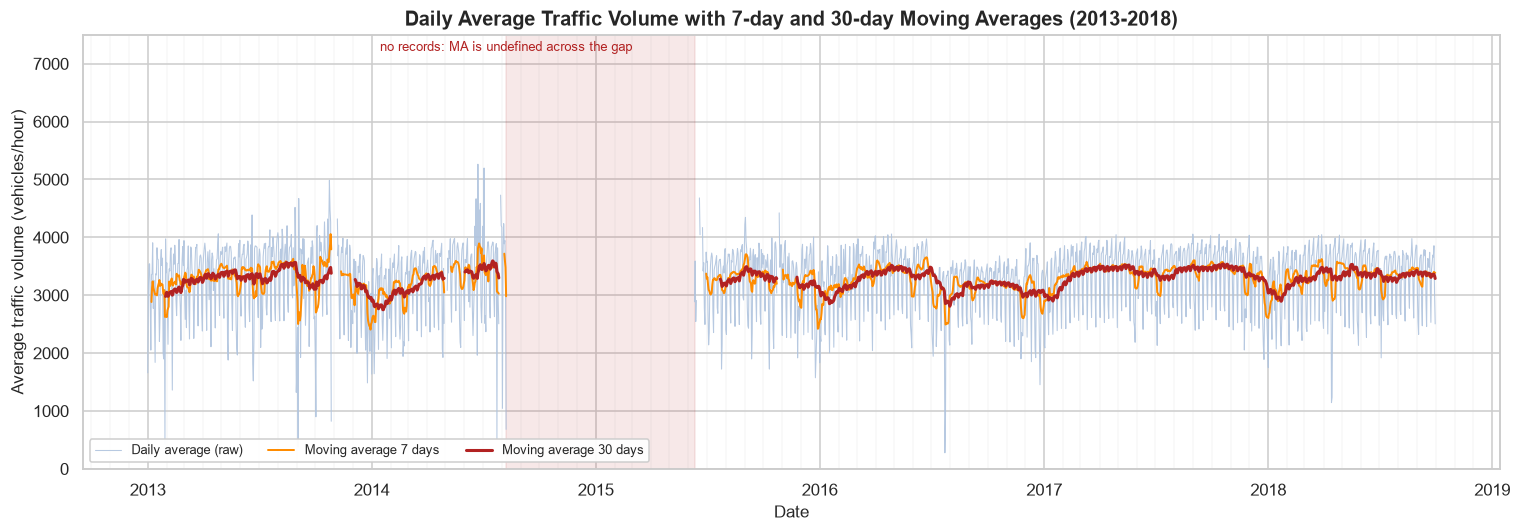

saved: reports\figures\05_moving_average.png


In [42]:
fig, ax = plt.subplots(figsize=(14, 5.0))
ax.plot(daily.index, daily.values, color="lightsteelblue", lw=0.7, alpha=0.9, label="Daily average (raw)")
ax.plot(ma7.index, ma7.values, color="darkorange", lw=1.3, label="Moving average 7 days")
ax.plot(ma30.index, ma30.values, color="firebrick", lw=2.0, label="Moving average 30 days")
ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)
ax.annotate("no records: MA is undefined across the gap", xy=(pd.Timestamp(gap["gap_start"]), 7100),
            xytext=(pd.Timestamp(gap["gap_start"]), 7220), ha="center", fontsize=8.5, color="firebrick")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set(title="Daily Average Traffic Volume with 7-day and 30-day Moving Averages (2013-2018)",
       xlabel="Date", ylabel="Average traffic volume (vehicles/hour)", ylim=(0, 7500))
ax.grid(axis="x", which="minor", alpha=0.15)
ax.legend(loc="lower left", ncol=3, fontsize=8.5, framealpha=0.95)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_moving_average.png")
plt.show()

print("saved:", (FIG_DIR / "05_moving_average.png").relative_to(ROOT))

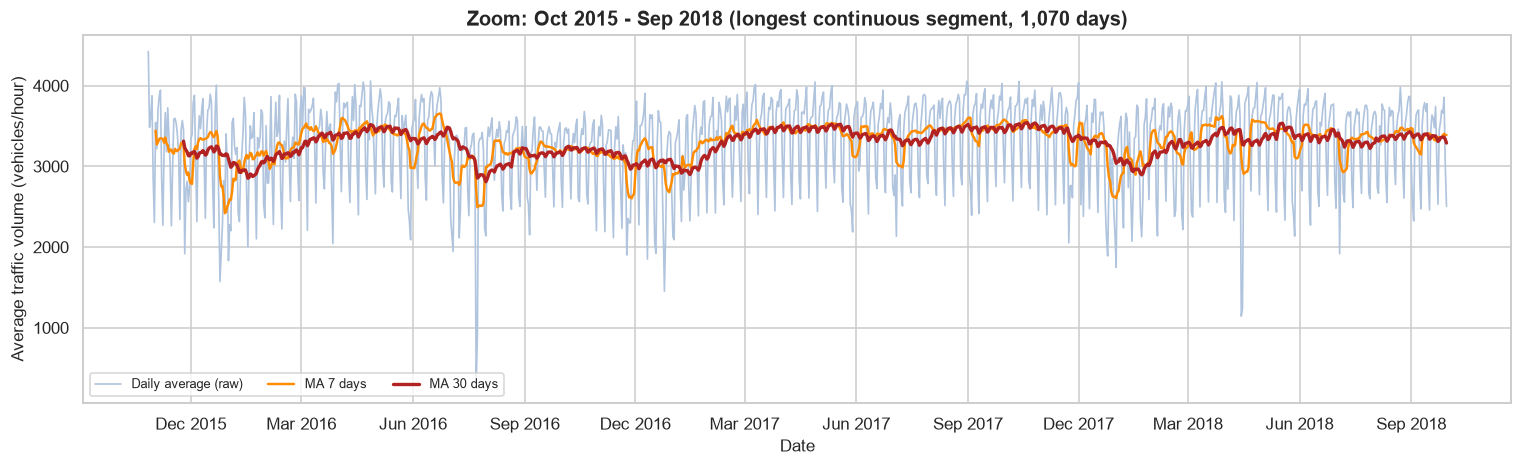

MA7: lag dengan korelasi tertinggi terhadap data asli = 3 hari (r = 0.423)
MA30: lag dengan korelasi tertinggi terhadap data asli = 15 hari (r = 0.409)


In [43]:
# Zoom on the longest continuous segment: does the 30-day window lose detail or react late?
zoom = daily.loc[longest_start:longest_end]
zoom_ma7 = ma7.loc[longest_start:longest_end]
zoom_ma30 = ma30.loc[longest_start:longest_end]

fig, ax = plt.subplots(figsize=(14, 4.4))
ax.plot(zoom.index, zoom.values, color="lightsteelblue", lw=1.1, label="Daily average (raw)")
ax.plot(zoom_ma7.index, zoom_ma7.values, color="darkorange", lw=1.6, label="MA 7 days")
ax.plot(zoom_ma30.index, zoom_ma30.values, color="firebrick", lw=2.2, label="MA 30 days")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set(title=f"Zoom: {longest_start.strftime('%b %Y')} - {longest_end.strftime('%b %Y')} "
             f"(longest continuous segment, {len(zoom):,} days)",
       xlabel="Date", ylabel="Average traffic volume (vehicles/hour)")
ax.legend(loc="lower left", ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

# Local lag of each MA behind the raw series inside the segment
for name, series in [("MA7", zoom_ma7), ("MA30", zoom_ma30)]:
    best_lag, best_corr = None, -2
    for lag in range(0, 31):
        corr = series.corr(zoom.shift(lag))
        if corr > best_corr:
            best_lag, best_corr = lag, corr
    print(f"{name}: lag dengan korelasi tertinggi terhadap data asli = {best_lag} hari (r = {best_corr:.3f})")

In [44]:
x_ord = mdates.date2num(daily.index.to_pydatetime())
fit_mask = daily.notna().to_numpy() & daily.index.to_series().between("2015-06-12", "2018-09-30").to_numpy()
coef = np.polyfit(x_ord[fit_mask], daily.to_numpy()[fit_mask], 1)
trend = np.polyval(coef, x_ord[fit_mask])
slope_per_year = coef[0] * 365.25
r = np.corrcoef(x_ord[fit_mask], daily.to_numpy()[fit_mask])[0, 1]
print(f"linear fit 2015-06-12 .. 2018-09-30 ({fit_mask.sum():,} days): "
      f"slope {slope_per_year:+,.0f} vehicles/hour per year, r = {r:.3f}, R^2 = {r**2:.3f}")

linear fit 2015-06-12 .. 2018-09-30 (1,198 days): slope +42 vehicles/hour per year, r = 0.072, R^2 = 0.005


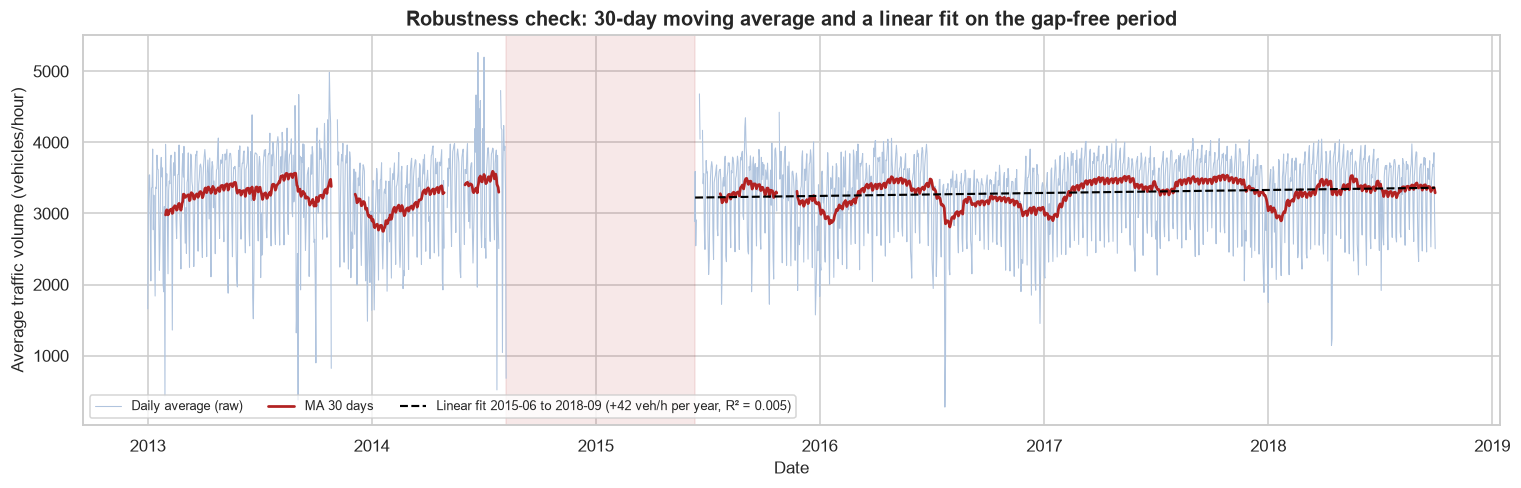

In [45]:
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.plot(daily.index, daily.values, color="lightsteelblue", lw=0.7, label="Daily average (raw)")
ax.plot(ma30.index, ma30.values, color="firebrick", lw=1.8, label="MA 30 days")
ax.plot(daily.index[fit_mask], trend, color="black", lw=1.4, ls="--",
        label=f"Linear fit 2015-06 to 2018-09 ({slope_per_year:+,.0f} veh/h per year, R\u00b2 = {r**2:.3f})")
ax.axvspan(gap["gap_start"], gap["gap_end"], color="firebrick", alpha=0.10)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set(title="Robustness check: 30-day moving average and a linear fit on the gap-free period",
       xlabel="Date", ylabel="Average traffic volume (vehicles/hour)")
ax.legend(loc="lower left", ncol=3, fontsize=8.5)
plt.tight_layout()
plt.show()

## 13. Key Findings & Insights

### 13.1 Bukti pendukung

In [46]:
hourly_all = proc.groupby("hour")["traffic_volume"].mean()
weekday_hourly = proc.loc[~proc["is_weekend"]].groupby("hour")["traffic_volume"].mean()
weekend_hourly = proc.loc[proc["is_weekend"]].groupby("hour")["traffic_volume"].mean()
evidence_rows = [
    ("overall daily mean (vehicles/hour)", f"{daily_avg.mean():,.0f}"),
    ("linear slope 2015-06..2018-09 (vehicles/hour per year)", f"{slope_per_year:+,.0f}"),
    ("linear fit R^2 (1,198 days)", f"{r ** 2:.4f}"),
    ("sd raw daily / MA7 / MA30", f"{daily.std():,.0f} / {ma7.std():,.0f} / {ma30.std():,.0f}"),
    ("valid MA7 / MA30 points (of 1,769 days with data)", f"{ma7.notna().sum():,} / {ma30.notna().sum():,}"),
    ("weekday mean / weekend mean", f"{wd.mean():,.0f} / {we.mean():,.0f}"),
    ("weekday-weekend gap", f"{wd.mean() - we.mean():,.0f}"),
    ("weekday peak hour / weekend peak hour",
     f"{weekday_hourly.idxmax():02d}:00 ({weekday_hourly.max():,.0f}) / "
     f"{weekend_hourly.idxmax():02d}:00 ({weekend_hourly.max():,.0f})"),
    ("lowest hour of day (all days)", f"{hourly_all.idxmin():02d}:00 ({hourly_all.min():,.0f})"),
    ("busiest complete day", f"{full_days_total.loc[full_days_total['total'].idxmax(), 'date'].date()} "
                             f"({full_days_total['total'].max():,} vehicles)"),
    ("quietest complete day", f"{full_days_total.loc[full_days_total['total'].idxmin(), 'date'].date()} "
                              f"({full_days_total['total'].min():,} vehicles)"),
    ("monthly mean: Jan / Aug (all days)",
     f"{month_mean.loc['Jan', 'mean']:,.0f} / {month_mean.loc['Aug', 'mean']:,.0f}"),
    ("monthly mean weekday: lowest / highest (month number)",
     f"{proc.loc[~proc['is_weekend']].groupby('month').traffic_volume.mean().idxmin()} / "
     f"{proc.loc[~proc['is_weekend']].groupby('month').traffic_volume.mean().idxmax()}"),
    ("missing hours", f"{len(missing):,} of {len(full_index):,} ({len(missing) / len(full_index):.1%})"),
]
evidence = pd.DataFrame(evidence_rows, columns=["metric", "value"])
evidence

,metric,value
0,overall daily mean (vehicles/hour),"3,281"
1,linear slope 2015-06..2018-09 (vehicles/hour p...,+42
2,"linear fit R^2 (1,198 days)",0.0052
3,sd raw daily / MA7 / MA30,604 / 230 / 167
4,"valid MA7 / MA30 points (of 1,769 days with data)","1,726 / 1,607"
5,weekday mean / weekend mean,"3,557 / 2,624"
6,weekday-weekend gap,934
7,weekday peak hour / weekend peak hour,"16:00 (6,241) / 13:00 (4,408)"
8,lowest hour of day (all days),03:00 (373)
9,busiest complete day,"2017-08-31 (97,332 vehicles)"


## 14. Conclusion

## 15. AI Usage Declaration

> Saya menyatakan bahwa saya **menggunakan** alat AI generatif (Claude Code) sebagai asisten implementasi kode dan visualisasi. Seluruh hasil dan interpretasi diverifikasi sendiri.

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|---|---|---|---|---|
| 1 | Claude Code | Pipeline data, EDA, 4 visualisasi wajib, Moving Average | Menghasilkan kode analisis dan visualisasi time series | Tinggi |


## 16. References

1. UCI Machine Learning Repository: Metro Interstate Traffic Volume (ID: 492)
2. Dokumentasi Python, pandas, numpy, matplotlib, seaborn, scipy